<a href="https://colab.research.google.com/github/rahs2015/mat422/blob/main/MAT422_%7C_HW_3_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MAT 422 | HW 3.3: Optimization and Gradient Descent

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 3.3.1: Necessary and sufficient conditions of local minimizers
To find a local min or max, there is a means that allows one to calculate such information through using the derivative. This is done through scowering the plot for points at which graph's derivative is equal to 0; these points of the graph are referred to as a critical point.

However, in this step, it was necessary that a second derivative was performed in order to evaluate the direction of the graph which is usually referred to as the concavity. The concavity of the graph determined from the 2nd derivative allows one to determine whether or not the graph is a local minimum or maximum which is simply seen from the positive or negative sign of the 2nd derivative.

Critical Point Analysis
x = -1.414 | h(x) = -1.000 | h'(x) = -0.000 | h''(x) = 16.000
x = 0.000 | h(x) = 3.000 | h'(x) = 0.000 | h''(x) = -8.000
x = 1.414 | h(x) = -1.000 | h'(x) = 0.000 | h''(x) = 16.000


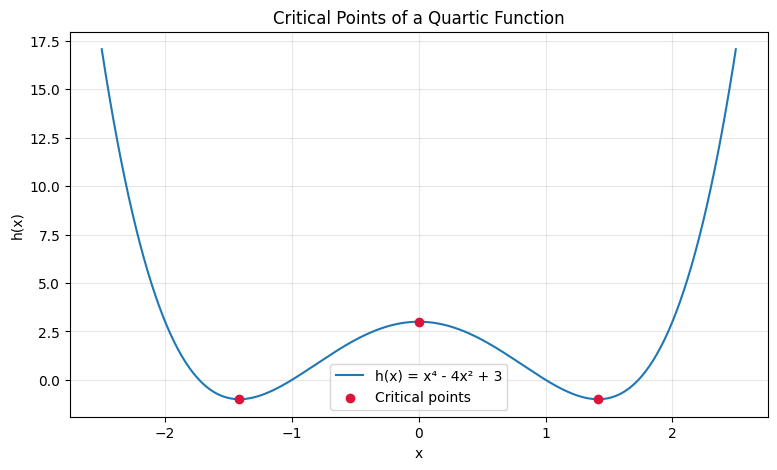

In [2]:
def h(x):
    return x**4 - 4*x**2 + 3

def dh(x):
    return 4*x**3 - 8*x

def d2h(x):
    return 12*x**2 - 8

# Critical points found by solving h'(x) = 0
critical_points = [-np.sqrt(2), 0, np.sqrt(2)]

print("Critical Point Analysis")
for point in critical_points:
    print(
        f"x = {point:.3f} | "
        f"h(x) = {h(point):.3f} | "
        f"h'(x) = {dh(point):.3f} | "
        f"h''(x) = {d2h(point):.3f}"
    )

x_values = np.linspace(-2.5, 2.5, 500)

plt.figure(figsize=(9, 5))
plt.plot(x_values, h(x_values), label="h(x) = x⁴ - 4x² + 3")
plt.scatter(
    critical_points,
    [h(point) for point in critical_points],
    color="crimson",
    zorder=3,
    label="Critical points"
)
plt.xlabel("x")
plt.ylabel("h(x)")
plt.title("Critical Points of a Quartic Function")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 3.3.2: Convexity and global minimizers
Convexity allows one to determine whether a function has an absolute minimum rather which allows one to make the argument about whether or not this specific point has points that are even lower. Using the 2nd derivative for the graph below, it is seen that the graph is convex throughout its interval and indeed the minimum is at -1.


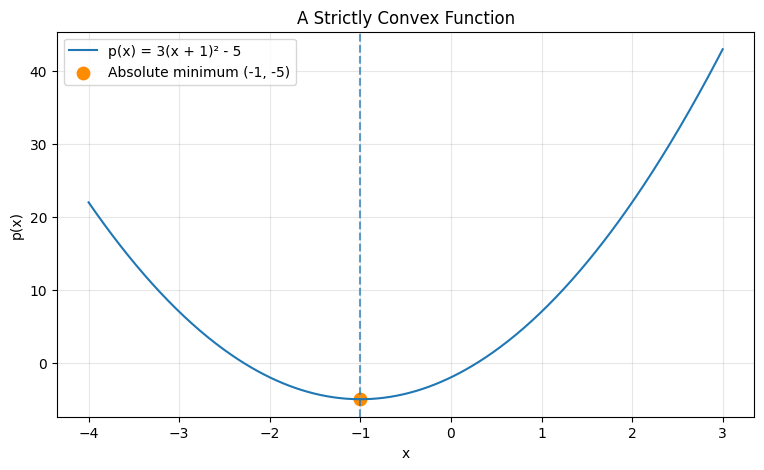

First derivative at x = -1: 0
Second derivative: 6
Minimum location: -1
Minimum function value: -5
p(-3) = 7
p(-2) = -2
p(-1) = -5
p(0) = -2
p(1) = 7


In [3]:

def p(x):
    return 3*(x + 1)**2 - 5

def dp(x):
    return 6*(x + 1)

def d2p(x):
    return 6

x_values = np.linspace(-4, 3, 400)

plt.figure(figsize=(9, 5))
plt.plot(x_values, p(x_values), label="p(x) = 3(x + 1)² - 5")
plt.scatter([-1], [p(-1)], color="darkorange",
            s=80, label="Absolute minimum (-1, -5)")
plt.axvline(-1, linestyle="--", alpha=0.7)
plt.xlabel("x")
plt.ylabel("p(x)")
plt.title("A Strictly Convex Function")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("First derivative at x = -1:", dp(-1))
print("Second derivative:", d2p(-1))
print("Minimum location:", -1)
print("Minimum function value:", p(-1))

# Test points on both sides of the minimum
test_points = [-3, -2, -1, 0, 1]

for point in test_points:
    print(f"p({point}) = {p(point)}")


# 3.3.3: Gradient descent
Gradient is again a means to find the minimum of a function; however, this starts with an estimate has iterative property that allows it to better estimate the minimum through the derivative of the function which dictates whether or not decrease the function's value.  The learning rate prescribed below at .15 is a way to control the how big each step is to minimize over and under estimation as well as the speed getting to the estimate.

Starting x: -3.0
Final x: 3.999842
Final function value: 2.0
Exact minimizer: x = 4, q(x) = 2


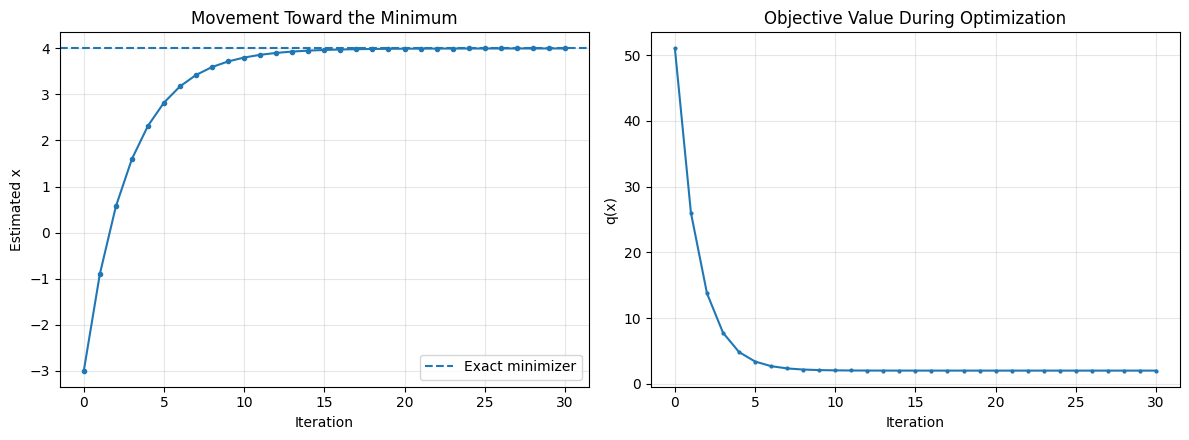

In [4]:

def q(x):
    return (x - 4)**2 + 2

def dq(x):
    return 2*(x - 4)

learning_rate = 0.15
current_x = -3.0
iterations = 30

x_history = [current_x]
value_history = [q(current_x)]

for step in range(iterations):
    current_x = current_x - learning_rate * dq(current_x)
    x_history.append(current_x)
    value_history.append(q(current_x))

print("Starting x:", x_history[0])
print("Final x:", round(x_history[-1], 6))
print("Final function value:", round(value_history[-1], 6))
print("Exact minimizer: x = 4, q(x) = 2")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(x_history, marker="o", markersize=3)
axes[0].axhline(4, linestyle="--", label="Exact minimizer")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Estimated x")
axes[0].set_title("Movement Toward the Minimum")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(value_history, marker=".", markersize=4)
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("q(x)")
axes[1].set_title("Objective Value During Optimization")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


* I explained my sections in words before my code.
* I double checked my core numerical claims such as expression, graphs, ...
* I changed and/or extended at least one to make this homework my own.
* I ran this from to bottom without issues.
* I am saving this to github under my mat422 repository.